<a href="https://colab.research.google.com/github/Salalahmdi/Advanced-Statistics-Transportation/blob/main/Assignment%201.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd

# Load dataset
df = pd.read_csv(
    "/content/pavement_transportation_master_dataset.csv"
)

# Overall statistics
overall = {
    "Road Class": "Overall",
    "Observations": len(df),
    "Mean AADT": df["AADT_veh_day"].mean(),
    "Mean IRI": df["IRI_m_per_km"].mean(),
    "Pearson r": df["AADT_veh_day"].corr(df["IRI_m_per_km"])
}

# Statistics by road class
results = []

for road_class, group in df.groupby("road_class"):
    results.append({
        "Road Class": road_class,
        "Observations": len(group),
        "Mean AADT": group["AADT_veh_day"].mean(),
        "Mean IRI": group["IRI_m_per_km"].mean(),
        "Pearson r": group["AADT_veh_day"].corr(
            group["IRI_m_per_km"]
        )
    })

# Combine results
results_df = pd.concat([
    pd.DataFrame([overall]),
    pd.DataFrame(results)
], ignore_index=True)

print(results_df.round(3).to_string(index=False))


Road Class  Observations  Mean AADT  Mean IRI  Pearson r
   Overall          2400  24257.662     3.401      0.477
  Arterial           816  27187.119     3.441      0.170
 Collector           632  10066.174     3.113      0.164
Expressway           448  62270.987     4.023      0.490
     Local           504   3520.788     3.144      0.085


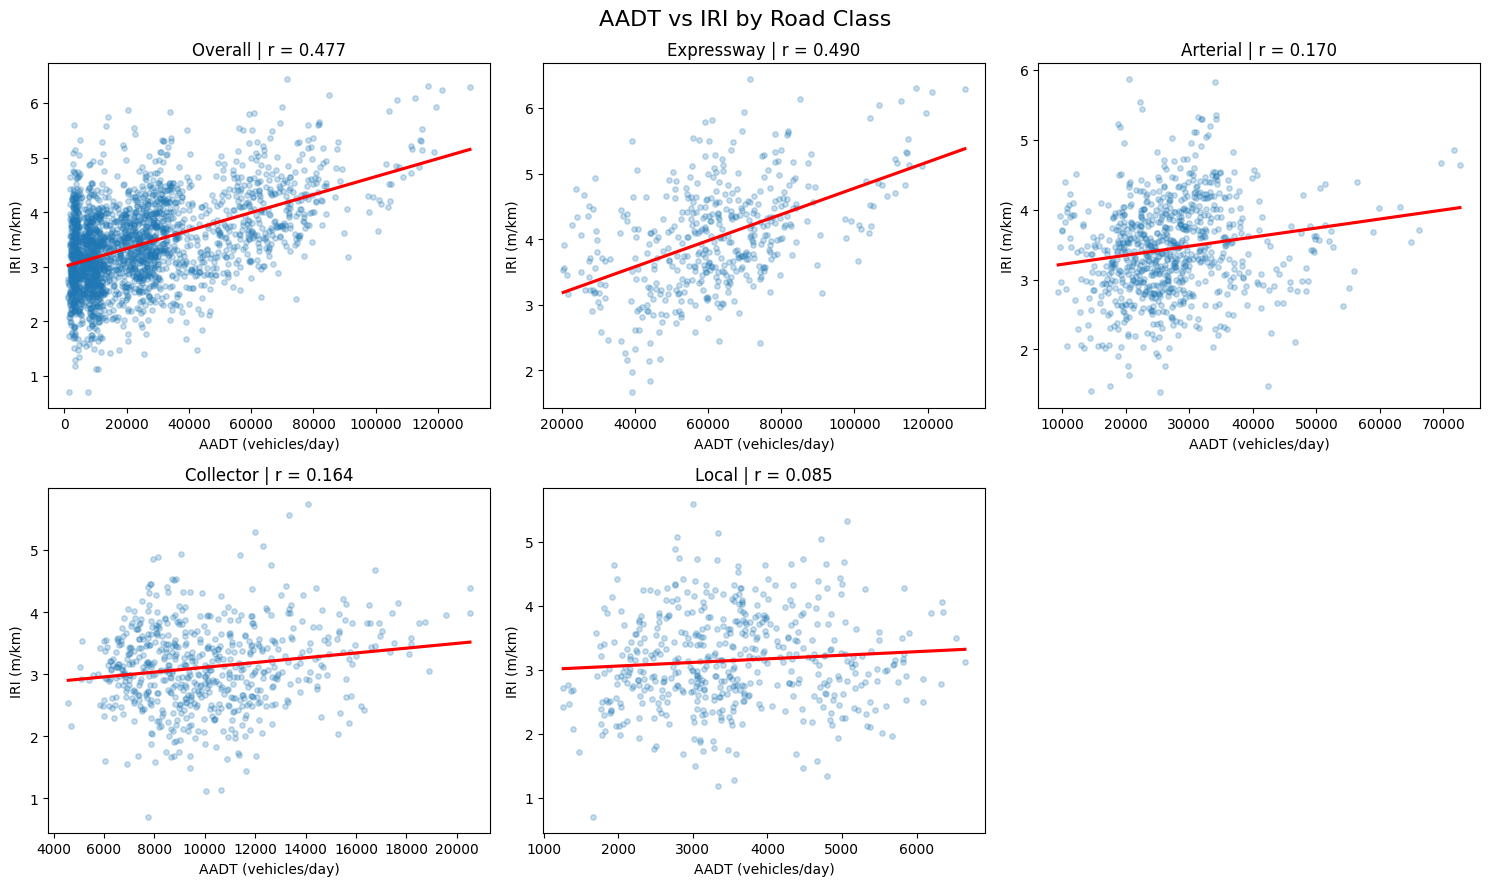

In [2]:

import matplotlib.pyplot as plt
import seaborn as sns

classes = ["Overall", "Expressway", "Arterial", "Collector", "Local"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, road_class in enumerate(classes):

    if road_class == "Overall":
        data = df
    else:
        data = df[df["road_class"] == road_class]

    r = data["AADT_veh_day"].corr(data["IRI_m_per_km"])

    sns.regplot(
        data=data,
        x="AADT_veh_day",
        y="IRI_m_per_km",
        ax=axes[i],
        scatter_kws={"alpha": 0.25, "s": 15},
        line_kws={"color": "red"},
        ci=None
    )

    axes[i].set_title(f"{road_class} | r = {r:.3f}")
    axes[i].set_xlabel("AADT (vehicles/day)")
    axes[i].set_ylabel("IRI (m/km)")

axes[5].axis("off")

plt.suptitle("AADT vs IRI by Road Class", fontsize=16)
plt.tight_layout()
plt.savefig("Assignment_01_Correlation.png", dpi=300)
plt.show()
